In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

In [2]:
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

## Part A

In [3]:
rng = np.random.default_rng(42)  # reset here so re-running this cell gives the same result
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))  # explore: random move
    return int(np.argmax(Q[state]))             # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

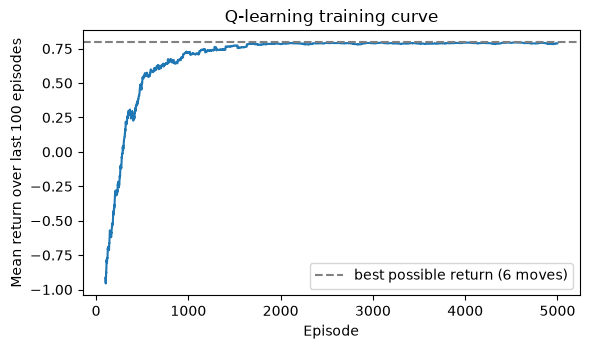

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


### Part A - Inspect
The training curve starts near -1.0 because early on the agent mostly moves randomly and falls into the trap a lot. It climbs fast over the first 1000 episodes, then flattens just under the 0.80 line once epsilon hits its 0.05 floor (around episode 2000). With exploration off, the greedy policy reached the goal in 200/200 episodes with a mean return of 0.8, which matches the shortest 6-move route (5 x -0.04 + 1 = 0.80). The training curve sits slightly below 0.80 because 5% of training moves are still random, while evaluation uses none.

## Part B

In [6]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)

policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


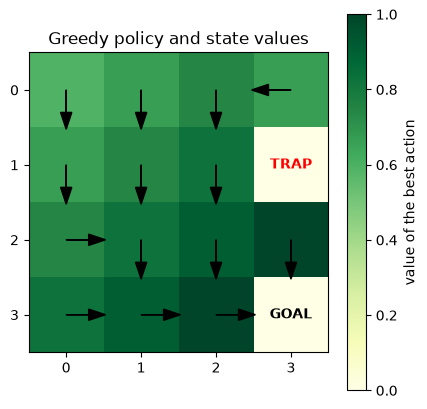

In [7]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")

### Part B - Inspect
I saved the Q-table to models/gridworld_q_table.npy and read the policy from the reloaded copy. From the start the policy goes down, down, right, down, right, right: (0,0) to (1,0) to (2,0) to (2,1) to (3,1) to (3,2) to GOAL, which is 6 moves. It never steps into the trap at (1,3). The cell above the trap (0,3) points left instead of down, and the cell below it (2,3) goes straight down into the goal. Values get higher the closer a cell is to the goal, with the darkest cells right next to GOAL. GOAL and TRAP look pale only because terminal cells never get updated, so their value stays 0.

### Try it yourself - prediction
Prediction: with a step cost of -0.5, every move now hurts a lot, so I expected the agent to still take the shortest route to the goal but with much lower values overall. I also thought it might start taking risks near the trap, since wandering around costs more than ending the episode.

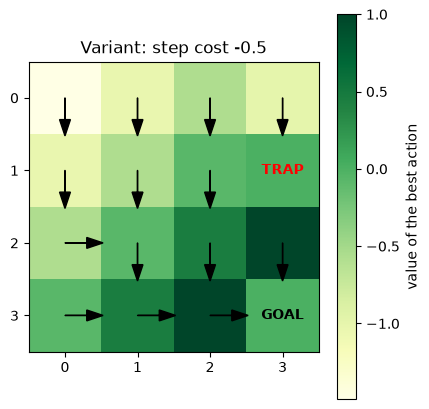

In [8]:
def train_variant(step_cost=-0.04, trap_reward=-1.0, gamma_v=0.95, episodes=5000, seed=42):
    r_ng = np.random.default_rng(seed)
    Qv = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0
    for _ in range(episodes):
        s = START
        for _ in range(100):
            a = int(r_ng.integers(4)) if r_ng.random() < eps else int(np.argmax(Qv[s]))
            r, c = s
            dr, dc = ACTIONS[a]
            ns = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
            rew, done = (1.0, True) if ns == GOAL else (trap_reward, True) if ns == TRAP else (step_cost, False)
            target = rew if done else rew + gamma_v * np.max(Qv[ns])
            Qv[s][a] += 0.15 * (target - Qv[s][a])
            s = ns
            if done:
                break
        eps = max(0.05, eps * 0.9985)
    return Qv

Q_variant = train_variant(step_cost=-0.5)
plot_policy(Q_variant, "Variant: step cost -0.5")

### Try it yourself - result
Result: The route from the start did not change. It still goes down, down, right, down, right, right to the goal and avoids the trap. What changed is the values: the colour scale now runs from roughly -1.4 to 1.0 instead of 0 to 1, and the top-left is the lowest because every extra move now costs -0.5. One cell did change: (0,3), above the trap, now points down into the trap instead of left. With -0.5 per step, walking away costs more than just ending the episode at -1.